# Mortes nas rodovias federais brasileiras — Análise Exploratória (PRF 2017–2025)

**Pergunta de negócio:** onde, quando e em que tipo de acidente as pessoas morrem nas rodovias federais, e quais ações teriam mais impacto para reduzir essas mortes?

Base: Dados Abertos da Polícia Rodoviária Federal (DATATRAN, agrupado por ocorrência), 2017–2025. A limpeza está em `src/preparar_dados.py`; este notebook parte do arquivo limpo.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.ticker as mtick
from pathlib import Path
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'font.size': 10})
AZUL, VERM, CINZA = '#1f4e79', '#c0392b', '#9aa5b1'
IMG = Path('../img'); IMG.mkdir(exist_ok=True)
df = pd.read_parquet('../dados/processados/acidentes_limpo.parquet')
def letal(g):
    t = df.groupby(g, observed=True).agg(acidentes=('id','size'), mortos=('mortos','sum'), fatais=('fatal','sum'))
    t['mortos_por_100'] = (100*t.mortos/t.acidentes).round(2)
    return t
df.shape

(632667, 32)

## 1. Qualidade dos dados e limpeza

In [2]:
print('Linhas:', len(df), '| ids duplicados:', df.id.duplicated().sum())
print('Período:', df.data.min().date(), 'a', df.data.max().date())
nulos = df.isna().sum(); print(nulos[nulos > 0])

Linhas: 632667 | ids duplicados: 0
Período: 2017-01-01 a 2025-12-31
classificacao      10
clima            8933
latitude           54
longitude          54
dtype: int64


O que foi tratado no pipeline:
- **Formato:** arquivos em `latin1`, separador `;`, decimal com vírgula (exceto 2024, com ponto) → números convertidos de forma única.
- **Taxonomia de causas:** a PRF mudou as categorias em 2021 (ex.: *"Falta de Atenção à Condução"* deixa de existir e surgem *"Reação tardia ou ineficiente do condutor"* e *"Ausência de reação do condutor"*). As ~90 causas foram agrupadas em **12 macrogrupos** comparáveis no tempo.
- **Tipos de acidente:** *Colisão lateral (mesmo sentido / sentido oposto)* → *Colisão lateral*; *Colisão com objeto (estático / em movimento)* → *Colisão com objeto*.
- **Coordenadas** fora do Brasil → nulas; `uso_solo = Sim` → urbano; `tracado_via` com múltiplos valores → primeiro valor.
- **Nulos remanescentes** são irrelevantes (clima "Ignorado" em 1,4% dos registros; 54 coordenadas inválidas).

## 2. Evolução anual

In [3]:
ano = letal('ano'); ano

,acidentes,mortos,fatais,mortos_por_100
ano,,,,
2017,89567,6248,5184,6.98
2018,69333,5274,4508,7.61
2019,67558,5340,4599,7.9
2020,63585,5292,4525,8.32
2021,64567,5397,4665,8.36
2022,64606,5441,4664,8.42
2023,67766,5627,4858,8.3
2024,73156,6160,5222,8.42
2025,72529,6043,5210,8.33


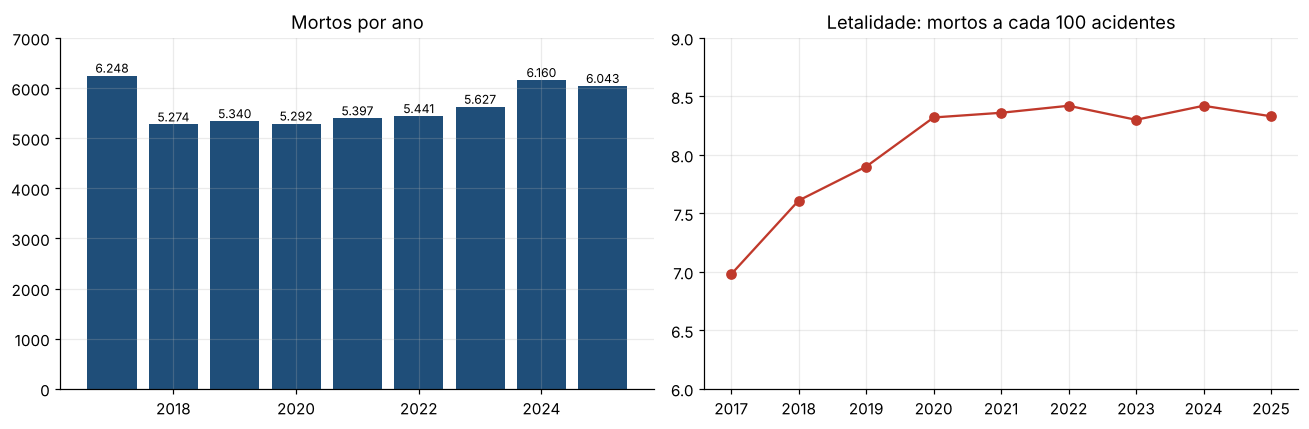

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(ano.index, ano.mortos, color=AZUL)
for x, y in zip(ano.index, ano.mortos): ax[0].text(x, y+60, f'{y:,}'.replace(',', '.'), ha='center', fontsize=8)
ax[0].set_title('Mortos por ano'); ax[0].set_ylim(0, 7000)
ax[1].plot(ano.index, ano.mortos_por_100, marker='o', color=VERM)
ax[1].set_title('Letalidade: mortos a cada 100 acidentes'); ax[1].set_ylim(6, 9)
plt.tight_layout(); plt.savefig(IMG/'01_evolucao_anual.png', bbox_inches='tight'); plt.show()

In [5]:
pd.crosstab(df.ano, df.classificacao)

classificacao,Com Vítimas Fatais,Com Vítimas Feridas,Sem Vítimas
ano,,,
2017,5184,53699,30683
2018,4508,49571,15253
2019,4599,51275,11683
2020,4525,47456,11602
2021,4665,48210,11691
2022,4664,48435,11506
2023,4858,51944,10963
2024,5222,56154,11779
2025,5209,56181,11138


**Leitura:** o número de acidentes caiu de 89,6 mil (2017) para 69,3 mil (2018), mas a queda está concentrada nos acidentes **sem vítimas** (30,7 mil → 15,3 mil) — padrão compatível com mudança na forma de registro, não com estradas mais seguras. As **mortes** são o indicador mais confiável: caíram até 2020 (5.292) e voltaram a subir, chegando a **6.160 em 2024 e 6.043 em 2025** — praticamente o patamar de 2017. A letalidade subiu de 7,0 para cerca de 8,3–8,4 mortos por 100 acidentes.

## 3. Tipo de acidente: frequência × gravidade

In [6]:
tipo = letal('tipo_acidente').query('acidentes > 1000').sort_values('mortos_por_100')
tipo['%_mortes'] = (100*tipo.mortos/df.mortos.sum()).round(1)
tipo.sort_values('mortos', ascending=False)

,acidentes,mortos,fatais,mortos_por_100,%_mortes
tipo_acidente,,,,,
Colisão frontal,41444,15693,11780,37.87,30.9
Atropelamento de Pedestre,28545,8232,8075,28.84,16.2
Saída de leito carroçável,100214,5988,5227,5.98,11.8
Colisão traseira,119326,5432,4822,4.55,10.7
Colisão transversal,78623,4139,3598,5.26,8.1
Colisão lateral,79616,3417,2903,4.29,6.7
Colisão com objeto,48126,2671,2350,5.55,5.3
Tombamento,51600,2266,2003,4.39,4.5
Capotamento,20242,885,788,4.37,1.7


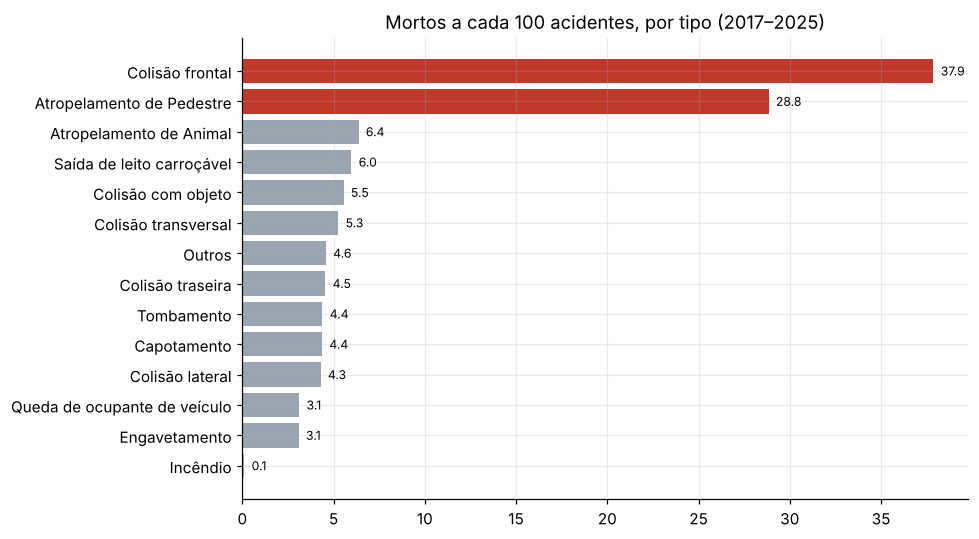

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
cores = [VERM if t in ('Colisão frontal','Atropelamento de Pedestre') else CINZA for t in tipo.index]
ax.barh(tipo.index, tipo.mortos_por_100, color=cores)
for i, v in enumerate(tipo.mortos_por_100): ax.text(v+.4, i, f'{v:.1f}', va='center', fontsize=8)
ax.set_title('Mortos a cada 100 acidentes, por tipo (2017–2025)')
plt.tight_layout(); plt.savefig(IMG/'02_letalidade_tipo.png', bbox_inches='tight'); plt.show()

**Leitura:** colisões traseiras são as mais frequentes, mas quem mata é a **colisão frontal**: 6,6% dos acidentes e **31% de todas as mortes** (37,9 mortos por 100 acidentes). **Atropelamento de pedestre** vem em seguida (28,8 por 100; 16% das mortes). Juntos, os dois tipos respondem por quase metade dos óbitos.

## 4. Causas (macrogrupos harmonizados)

In [8]:
causa = letal('causa_grupo').sort_values('mortos', ascending=False)
causa['%_mortes'] = (100*causa.mortos/df.mortos.sum()).round(1); causa

,acidentes,mortos,fatais,mortos_por_100,%_mortes
causa_grupo,,,,,
Desatenção/reação tardia,242551,12762,11184,5.26,25.1
Ultrapassagem/contramão/manobra,56176,9186,7131,16.35,18.1
Pedestre,21310,6286,6186,29.5,12.4
Velocidade incompatível,53693,5749,4637,10.71,11.3
Desrespeito a normas/preferência,75599,5476,4810,7.24,10.8
Sono/mal súbito do condutor,28159,3335,2753,11.84,6.6
Via/infraestrutura,42429,2652,2172,6.25,5.2
Álcool/drogas (condutor),43125,2512,2194,5.82,4.9
Veículo (falha mecânica/carga),47016,1605,1254,3.41,3.2


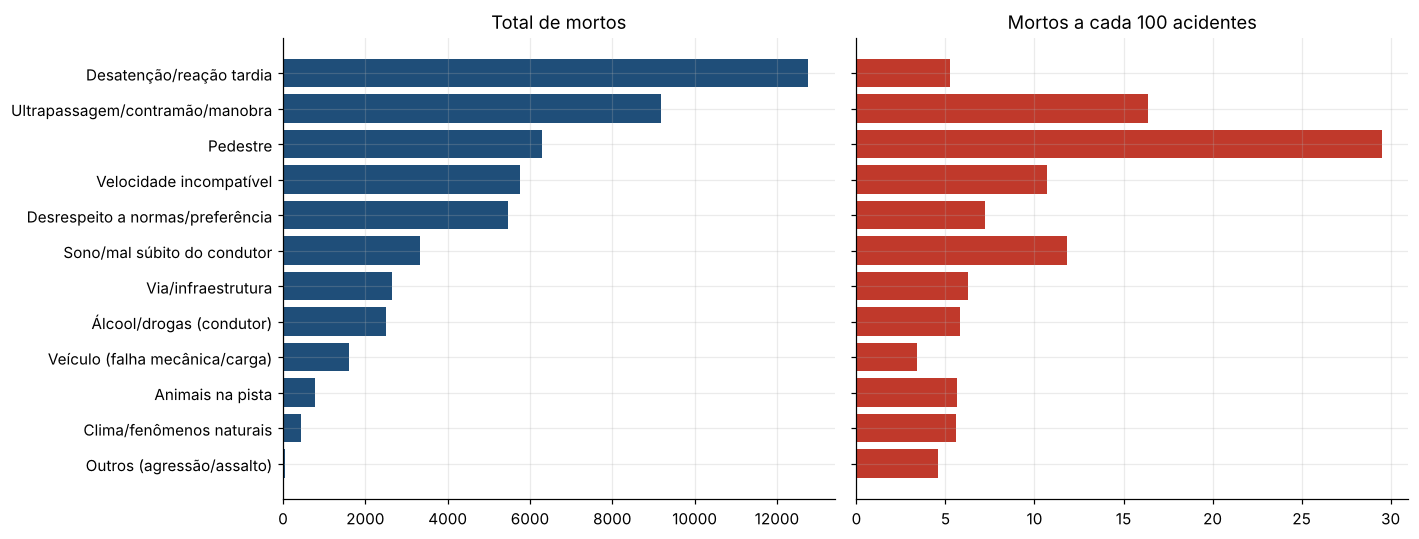

In [9]:
c = causa.sort_values('mortos')
fig, ax = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
ax[0].barh(c.index, c.mortos, color=AZUL); ax[0].set_title('Total de mortos')
ax[1].barh(c.index, c.mortos_por_100, color=VERM); ax[1].set_title('Mortos a cada 100 acidentes')
plt.tight_layout(); plt.savefig(IMG/'03_causas.png', bbox_inches='tight'); plt.show()

**Leitura:** *desatenção/reação tardia* é a causa mais comum e soma mais mortes em volume (pela frequência), mas as causas mais letais são **pedestre** (29,5 por 100), **ultrapassagem/contramão** (16,4), **sono/mal súbito** (11,8) e **velocidade** (10,7). Ultrapassagem indevida e contramão estão diretamente ligadas à colisão frontal — e são evitáveis com engenharia (pista dupla, faixa adicional, barreira central) e fiscalização.

## 5. Quando: hora do dia, fase do dia e fim de semana

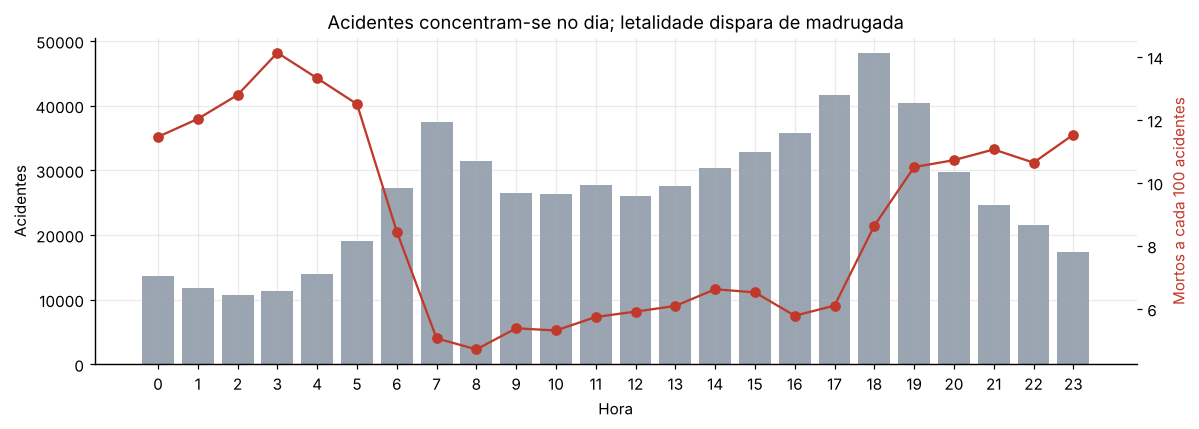

In [10]:
hora = letal('hora')
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(hora.index, hora.acidentes, color=CINZA, label='Acidentes')
ax2 = ax1.twinx(); ax2.plot(hora.index, hora.mortos_por_100, color=VERM, marker='o', label='Mortos/100')
ax1.set_xlabel('Hora'); ax1.set_ylabel('Acidentes'); ax2.set_ylabel('Mortos a cada 100 acidentes', color=VERM)
ax2.grid(False); ax1.set_xticks(range(24)); ax1.set_title('Acidentes concentram-se no dia; letalidade dispara de madrugada')
plt.tight_layout(); plt.savefig(IMG/'04_hora.png', bbox_inches='tight'); plt.show()

In [11]:
display(letal('fase_dia')); display(letal('fim_de_semana'))

,acidentes,mortos,fatais,mortos_por_100
fase_dia,,,,
Amanhecer,30820,3716,3132,12.06
Anoitecer,34672,2560,2218,7.38
Plena Noite,219959,24534,21437,11.15
Pleno dia,347216,20012,16648,5.76


,acidentes,mortos,fatais,mortos_por_100
fim_de_semana,,,,
False,424249,30901,26592,7.28
True,208418,19921,16843,9.56


**Leitura:** a maior parte dos acidentes acontece de dia (pico às 18h), mas a letalidade quase **triplica de madrugada** (14,1 mortos por 100 às 3h contra 4,7 às 8h). Acidentes em plena noite são 35% do total e 48% das mortes. No fim de semana, a letalidade é 31% maior (9,6 vs 7,3).

## 6. Onde: UFs e trechos de BR

In [12]:
uf = letal('uf').sort_values('mortos', ascending=False)
uf.head(10)

,acidentes,mortos,fatais,mortos_por_100
uf,,,,
MG,83417,6637,5457,7.96
PR,70624,5033,4339,7.13
BA,33974,4829,3893,14.21
SC,74668,3474,3021,4.65
RS,44121,2864,2424,6.49
PE,26007,2804,2518,10.78
RJ,47072,2790,2500,5.93
GO,30361,2662,2186,8.77
MA,10871,2162,1817,19.89


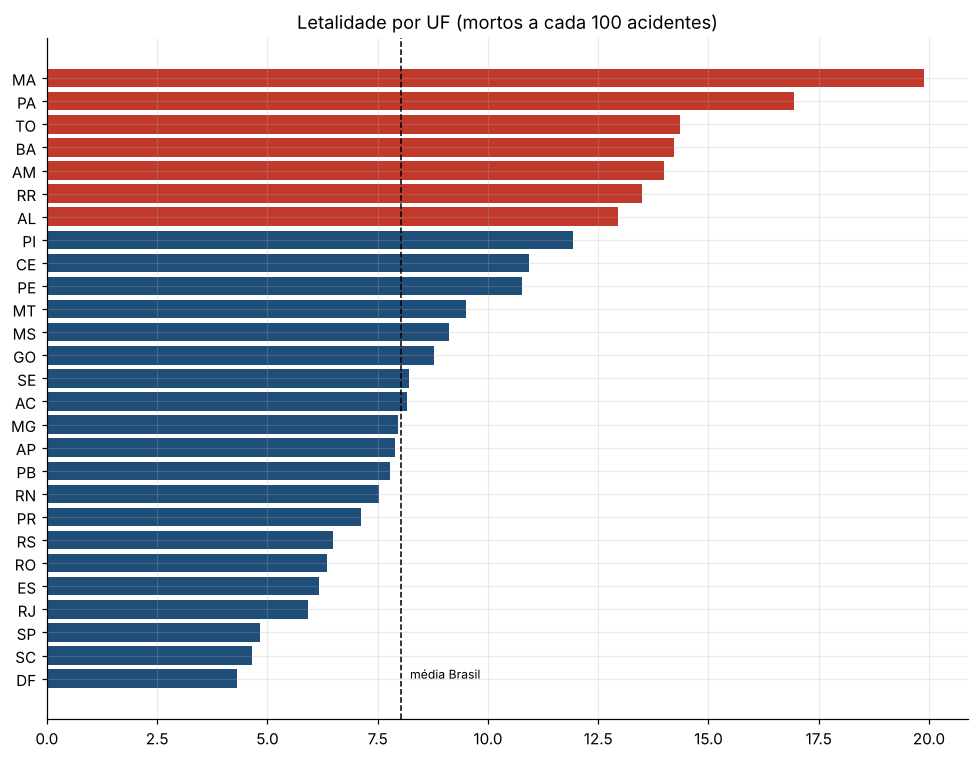

In [13]:
u = uf[uf.acidentes > 1000].sort_values('mortos_por_100')
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(u.index, u.mortos_por_100, color=[VERM if v > 12 else AZUL for v in u.mortos_por_100])
ax.axvline(100*df.mortos.sum()/len(df), color='k', ls='--', lw=1); ax.text(100*df.mortos.sum()/len(df)+.2, 0, 'média Brasil', fontsize=8)
ax.set_title('Letalidade por UF (mortos a cada 100 acidentes)')
plt.tight_layout(); plt.savefig(IMG/'05_uf.png', bbox_inches='tight'); plt.show()

In [14]:
br = pd.read_csv('../dados/processados/agg_br.csv').sort_values('mortos', ascending=False)
br[['trecho','acidentes','mortos','mortos_por_100']].head(10)

,trecho,acidentes,mortos,mortos_por_100
132,BR-381/MG,25419,1529,6.02
45,BR-116/SP,29886,1465,4.90
98,BR-277/PR,18526,1367,7.38
22,BR-101/BA,8191,1354,16.53
9,BR-040/MG,16605,1207,7.27
39,BR-116/MG,11351,1185,10.44
29,BR-101/SC,37259,1142,3.07
37,BR-116/BA,8352,1129,13.52
131,BR-376/PR,16685,1069,6.41
26,BR-101/RJ,16604,1030,6.20


**Leitura:** em volume, **MG** (6.637 mortos), **PR** (5.033) e **BA** (4.829) lideram. Em letalidade, o Norte/Nordeste se destaca: **MA** tem 19,9 mortos por 100 acidentes — mais de 2× a média nacional (8,0), seguido de PA (16,9), TO (14,4) e BA (14,2). Santa Catarina, com muitos acidentes, tem letalidade baixa (4,7), o que sugere efeito de pista duplicada (BR-101/SC tem 3,1). Os trechos com mais mortes são **BR-381/MG, BR-116/SP, BR-277/PR e BR-101/BA** — este último com letalidade de 16,5.

## 7. Condições da via e do ambiente

In [15]:
display(letal('tipo_pista')); display(letal('urbano')); display(letal('clima').query('acidentes > 1000').sort_values('mortos_por_100'))

,acidentes,mortos,fatais,mortos_por_100
tipo_pista,,,,
Dupla,263058,12985,11988,4.94
Múltipla,53912,2223,2089,4.12
Simples,315697,35614,29358,11.28


,acidentes,mortos,fatais,mortos_por_100
urbano,,,,
False,358739,37654,31213,10.5
True,273928,13168,12222,4.81


,acidentes,mortos,fatais,mortos_por_100
clima,,,,
Sol,42336,2569,2184,6.07
Garoa/Chuvisco,21990,1493,1233,6.79
Chuva,70382,5086,4097,7.23
Nublado,104786,8147,7057,7.77
Céu Claro,377724,31729,27320,8.4
Vento,1219,104,94,8.53
Nevoeiro/Neblina,5266,717,599,13.62


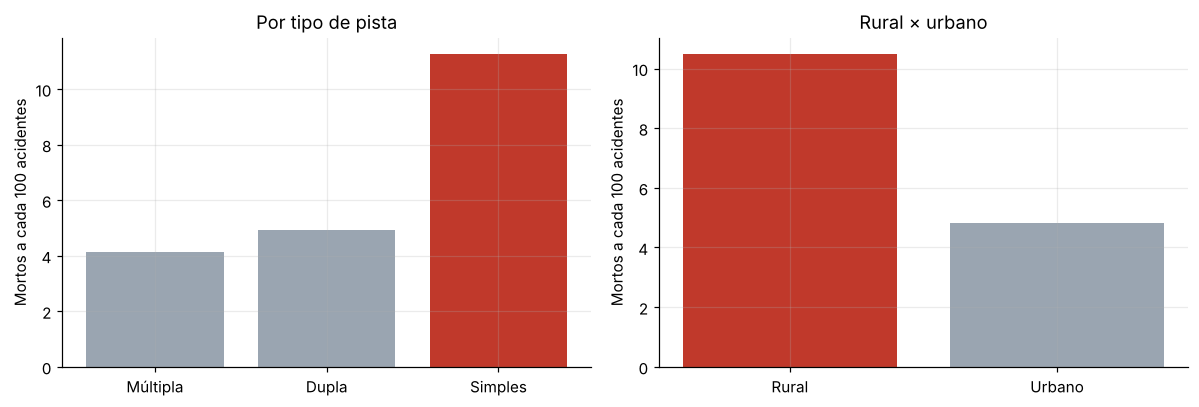

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
p = letal('tipo_pista').sort_values('mortos_por_100')
ax[0].bar(p.index, p.mortos_por_100, color=[CINZA, CINZA, VERM]); ax[0].set_title('Por tipo de pista')
u = letal('urbano'); u.index = ['Rural', 'Urbano']
ax[1].bar(u.index, u.mortos_por_100, color=[VERM, CINZA]); ax[1].set_title('Rural × urbano')
for a in ax: a.set_ylabel('Mortos a cada 100 acidentes')
plt.tight_layout(); plt.savefig(IMG/'06_pista_solo.png', bbox_inches='tight'); plt.show()

**Leitura:** em **pista simples** morrem 11,3 pessoas a cada 100 acidentes, contra 4,9 na dupla — 2,3× mais. Pistas simples concentram 50% dos acidentes e **70% das mortes**. Trechos rurais têm letalidade 2,2× maior que os urbanos. O clima pesa menos do que se imagina: chuva tem letalidade *menor* que céu claro (provável redução de velocidade); a exceção é **neblina** (13,6).

## 8. Correlações

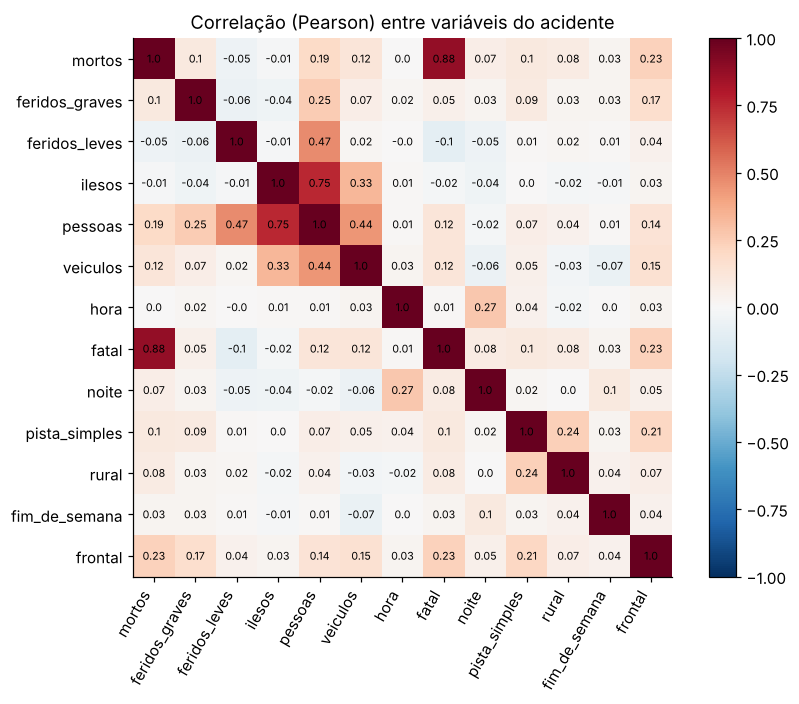

fatal             1.00
mortos            0.88
frontal           0.23
pessoas           0.12
veiculos          0.12
pista_simples     0.10
rural             0.08
noite             0.08
feridos_graves    0.05
fim_de_semana     0.03
hora              0.01
ilesos           -0.02
feridos_leves    -0.10
Name: fatal, dtype: float64

In [17]:
num = df[['mortos','feridos_graves','feridos_leves','ilesos','pessoas','veiculos','hora','fatal']].copy()
num['noite'] = df.noite.astype(int); num['pista_simples'] = df.tipo_pista.eq('Simples').astype(int)
num['rural'] = (~df.urbano).astype(int); num['fim_de_semana'] = df.fim_de_semana.astype(int)
num['frontal'] = df.tipo_acidente.eq('Colisão frontal').astype(int)
corr = num.corr().round(2)
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=60, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, corr.iloc[i, j], ha='center', va='center', fontsize=7)
plt.colorbar(im, fraction=.04); ax.set_title('Correlação (Pearson) entre variáveis do acidente')
plt.tight_layout(); plt.savefig(IMG/'07_correlacao.png', bbox_inches='tight'); plt.show()
corr['fatal'].sort_values(ascending=False)

**Leitura:** correlações lineares com um evento raro (7% dos acidentes são fatais) são naturalmente baixas. Ainda assim, as maiores associações positivas com *fatal* são **colisão frontal**, **pista simples**, **rural** e **noite**. Como essas variáveis se sobrepõem (ex.: trecho rural costuma ser pista simples), a seção seguinte estima o efeito de cada uma isoladamente.

## 9. Modelagem: o que aumenta a chance de um acidente ser fatal?

Regressão logística (`statsmodels`) com variável-alvo `fatal` (houve ao menos 1 morto). Os coeficientes viram **razões de chance (odds ratio)**: OR = 2 significa o dobro da chance de morte, mantidas as demais variáveis constantes. Categorias de referência: pista dupla, urbano, pleno dia, dia útil, colisão traseira, desatenção.

In [18]:
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score
m = df.dropna(subset=['tipo_acidente']).copy()
m = m[~m.tipo_acidente.isin(['Não informado','Outros'])]
m['rural'] = (~m.urbano).astype(int); m['fds'] = m.fim_de_semana.astype(int)
m['pista'] = m.tipo_pista.replace({'Múltipla': 'Dupla'})
treino = m.sample(frac=.7, random_state=42); teste = m.drop(treino.index)
f = ("fatal ~ C(pista, Treatment('Dupla')) + rural + C(fase_dia, Treatment('Pleno dia')) + fds"
     " + C(tipo_acidente, Treatment('Colisão traseira')) + C(causa_grupo, Treatment('Desatenção/reação tardia'))")
mod = smf.logit(f, data=treino).fit(disp=0)
auc = roc_auc_score(teste.fatal, mod.predict(teste))
print(f'Pseudo-R² (McFadden): {mod.prsquared:.3f} | AUC no teste (30%): {auc:.3f} | n treino = {len(treino):,}')

Pseudo-R² (McFadden): 0.160 | AUC no teste (30%): 0.781 | n treino = 439,962


In [19]:
ci = np.exp(mod.conf_int()); orr = pd.DataFrame({'OR': np.exp(mod.params), 'IC95_inf': ci[0], 'IC95_sup': ci[1], 'p': mod.pvalues})
orr = orr.drop('Intercept')
import re
ROT = {'pista': 'Pista: ', 'fase_dia': 'Fase do dia: ', 'tipo_acidente': 'Tipo: ', 'causa_grupo': 'Causa: '}
def rotulo(t):
    r = re.match(r"C\((\w+), Treatment\('[^']+'\)\)\[T\.(.+)\]", t)
    return ROT[r.group(1)] + r.group(2) if r else {'rural': 'Trecho rural', 'fds': 'Fim de semana'}.get(t, t)
orr.index = orr.index.map(rotulo)
orr = orr.round(3).sort_values('OR', ascending=False); orr

,OR,IC95_inf,IC95_sup,p
Tipo: Atropelamento de Pedestre,6.564,6.134,7.023,0.000
Tipo: Colisão frontal,5.419,5.163,5.688,0.000
Trecho rural,2.097,2.036,2.159,0.000
Fase do dia: Amanhecer,1.955,1.856,2.059,0.000
Fase do dia: Plena Noite,1.768,1.720,1.817,0.000
Causa: Velocidade incompatível,1.738,1.660,1.820,0.000
Causa: Pedestre,1.707,1.593,1.830,0.000
Causa: Ultrapassagem/contramão/manobra,1.562,1.495,1.633,0.000
Pista: Simples,1.496,1.454,1.540,0.000
Causa: Sono/mal súbito do condutor,1.490,1.408,1.577,0.000


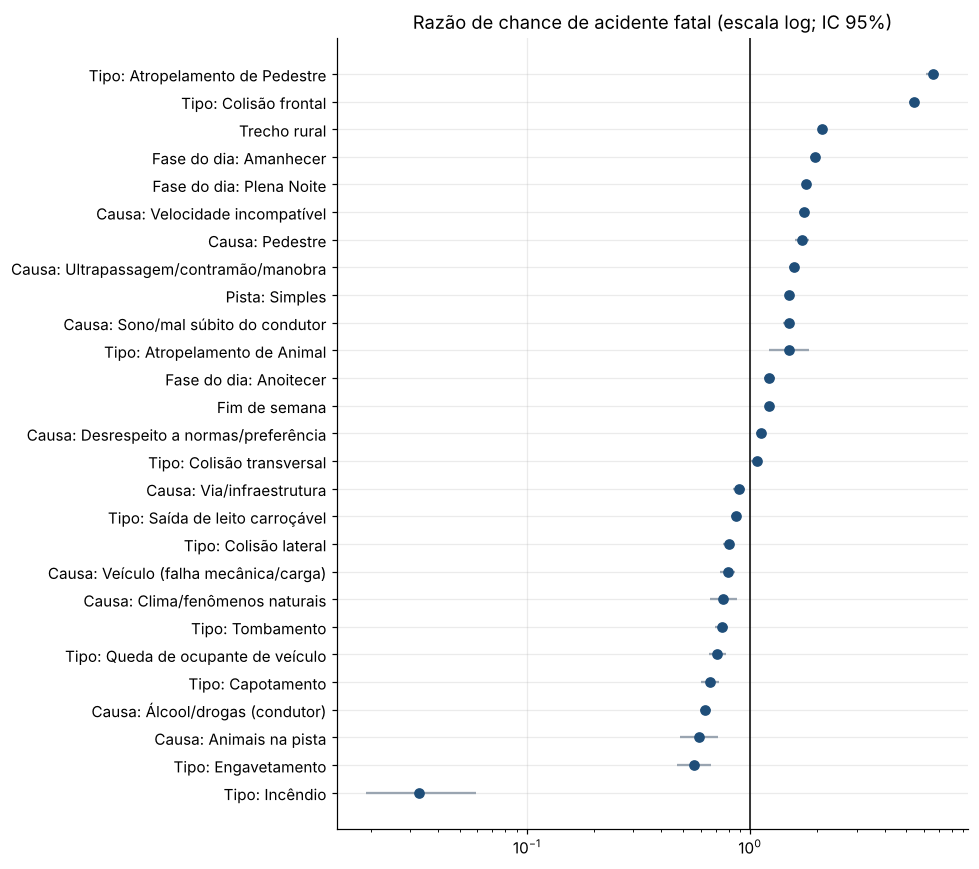

In [20]:
o = orr[orr.p < .05].sort_values('OR')
fig, ax = plt.subplots(figsize=(9, 8))
ax.errorbar(o.OR, range(len(o)), xerr=[o.OR-o.IC95_inf, o.IC95_sup-o.OR], fmt='o', color=AZUL, ecolor=CINZA)
ax.axvline(1, color='k', lw=1); ax.set_xscale('log'); ax.set_yticks(range(len(o))); ax.set_yticklabels(o.index)
ax.set_title('Razão de chance de acidente fatal (escala log; IC 95%)')
plt.tight_layout(); plt.savefig(IMG/'08_odds_ratio.png', bbox_inches='tight'); plt.show()

**Leitura:** com AUC de 0,78 no conjunto de teste, o modelo separa razoavelmente acidentes fatais dos não fatais. Mantidas as demais variáveis constantes:
- **Atropelamento de pedestre** (OR 6,6) e **colisão frontal** (OR 5,4) multiplicam a chance de morte em relação à colisão traseira;
- **trecho rural** dobra a chance (OR 2,1); **amanhecer** (1,96) e **plena noite** (1,77) também elevam o risco frente ao pleno dia;
- **velocidade incompatível** (1,74), **ultrapassagem/contramão** (1,56) e **sono/mal súbito** (1,49) são as causas mais agravantes frente à desatenção;
- **pista simples** aumenta a chance em 50% (OR 1,50) mesmo depois de controlar o tipo de colisão e o trecho rural; o **fim de semana**, em 21%.

Ressalva: *álcool* aparece com OR < 1, o que provavelmente reflete o registro (o teste do condutor é feito com mais frequência em acidentes em que ele sobrevive), não um efeito protetor. O modelo é **explicativo**, não causal: indica associações robustas para priorizar ações, não prova o efeito de uma intervenção.

## 10. Conclusões
1. As mortes não estão caindo: 6.043 em 2025, praticamente o patamar de 2017, e a letalidade subiu de 7,0 para ~8,3 por 100 acidentes. A meta do PNATRANS (reduzir mortes à metade até 2030) está distante.
2. Colisão frontal + atropelamento = ~47% das mortes, com apenas 11% dos acidentes.
3. Pista simples e trecho rural concentram o risco: 70% das mortes acontecem em pista simples.
4. Noite e madrugada: letalidade ~2× maior que de dia.
5. Prioridades geográficas: MA, PA, TO e BA (letalidade) e BR-381/MG, BR-116/SP, BR-277/PR, BR-101/BA (volume).